In [62]:
import numpy as np
import pandas as pd
from pathlib import Path
import pandas as pd
from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit.Geometry import Point3D
import subprocess, re, shutil

In [63]:
SEED = 114514
HARTREE = 2625.5

In [64]:
def xyz_to_mol(smiles, path):
    mol = Chem.AddHs(Chem.MolFromSmiles(smiles))      # 拓扑 + 氢（顺序：重原子，然后氢）
    lines = open(path).read().splitlines()            # 读整个文件
    n = int(lines[0])                                 # 第1行 = 原子数
    xyz = np.array([l.split()[1 : ] for l in lines[2 : 2 + n]], float)  # 取后3列 = 坐标
    conf = Chem.Conformer(n)                          # 建一个空构象
    for i, p in enumerate(xyz):
        conf.SetAtomPosition(i, Point3D(*p))          # 第 i 个原子 ← 第 i 行坐标
    mol.AddConformer(conf, assignId = True)           # 装进分子
    return mol

def frag_indices(mol, i, j):
    em = Chem.RWMol(mol)
    em.RemoveBond(i, j)
    return Chem.GetMolFrags(em, asMols = False)

def write_xyz(path, mol, idx):
    conf = mol.GetConformer()
    with open(path, "w") as f:
        f.write(f"{len(idx)}\n\n")
        for i in idx:
            a = mol.GetAtomWithIdx(i)
            p = conf.GetAtomPosition(i)
            f.write(f"{a.GetSymbol():2s}{p.x:16.8f}{p.y:16.8f}{p.z:16.8f}\n")

def run_xtb(folder, xyz, chrg, uhf, *flags):
    with open(folder / "xtb.out", "w") as f:
        p = subprocess.run([str(XTB), xyz, "--gfn", "2",
                            "--chrg", str(chrg), "--uhf", str(uhf), *flags,
                            "P", "4", "--iterations", "1000", "--etemp", "1000", "--json"],
                           cwd = folder, stdout = f, stderr = subprocess.STDOUT)
        return p.returncode

def read_energy(path):
    text = path.read_text(encoding = "utf-8")
    return float(re.search(r'"total energy"\s*:\s*(-?[\d.eE+-]+)', text).group(1))

JUNK = ("charges", "wbo", "xtbrestart", "xtbtopo.mol", "xtbout.json", "xtb.out", "xtbopt.xyz", "xtbopt.log", ".xtboptok")
def clean(folder):
    for f in folder.iterdir():
        if f.name in JUNK:
            f.unlink()

In [65]:
def frag_q_uhf(mol, idx):
    q = sum(mol.GetAtomWithIdx(k).GetFormalCharge() for k in idx)
    z = sum(mol.GetAtomWithIdx(k).GetAtomicNum() for k in idx)
    return q, (z - q) % 2

def bde_of_bond(mol, x, n, folder):
    frags = frag_indices(mol, x, n)
    if len(frags) != 2:
        return None
    f1, f2 = frags

    qp, up = frag_q_uhf(mol, range(mol.GetNumAtoms()))
    qa, ua = frag_q_uhf(mol, f1)
    qb, ub = frag_q_uhf(mol, f2)

    folder.mkdir(exist_ok = True)
    write_xyz(folder / "parent.xyz", mol, range(mol.GetNumAtoms()))
    write_xyz(folder / "fragA.xyz", mol, f1)
    write_xyz(folder / "fragB.xyz", mol, f2)

    if not (folder / "parent.json").exists():
        run_xtb(folder, "parent.xyz", qp, up, "--scc")
        shutil.copy2(folder / "xtbout.json", folder / "parent.json")
        clean(folder)
    Ep = read_energy(folder / "parent.json")

    E_sum = 0.0
    for name, q, uhf in (("fragA", qa, ua), ("fragB", qb, ub)):
        spins = (1, ) if uhf == 1 else (0, 2)
        e_best = None
        for s in spins:
            sub = folder / f"{name}_u{s}.json"
            if not sub.exists():
                run_xtb(folder, f"{name}.xyz", q, s, "--scc")
                shutil.copy2(folder / "xtbout.json", sub)
                clean(folder)
            e = read_energy(sub)
            e_best = e if e_best is None else min(e_best, e)
        E_sum += e_best
    return (E_sum - Ep) * HARTREE

In [66]:
# 处理 .xlsx 数据，生成 mol 类
file = Path.cwd().parent / "data" / "fixed.xlsx"
df = pd.read_excel(file)

STORE = Path(r"C:\Users\czywg\Desktop\Parents")
mols = []
for i in range(len(df)):
    mols.append(xyz_to_mol(df.loc[i, "SMILES"], STORE / f"parent_{i:04d}" / "conf.xyz"))
df["ROMol"] = mols
PandasTools.RenderImagesInAllDataFrames()

In [67]:
WORK = Path(r"C:\Users\czywg\Desktop\Programmer_czy\xtb_work\BDE")
XTB = Path(r"C:\Users\czywg\miniconda3\envs\xtb\Library\bin\xtb.exe")
FILE = Path(r"C:\Users\czywg\Desktop\Parents")

ALLPAT = [Chem.MolFromSmarts(p) for p in (
    "[#6]-[N+](=O)[O-]",          # C-NO2
    "[#7]-[N+](=O)[O-]",          # N-NO2
    "[#8]-[N+](=O)[O-]",          # O-NO2
)]

trigger_atoms = []

for cur, i in enumerate(sorted(FILE.glob("parent_*"))):
    mol = Chem.AddHs(df["ROMol"][cur])
    wbo = pd.read_csv(i / "wbo", sep = r"\s+", names=["a", "b", "wbo"])
    wbo_d = {(min(a, b) - 1, max(a, b) - 1) : w for a, b, w in wbo.values}

    for p in ALLPAT:
        minn = np.nan
        atoms = None
        for x, n, *_ in mol.GetSubstructMatches(p):
            w = wbo_d.get((min(x, n), max(x, n)))
            if w is not None and (minn != minn or w < minn):
                minn = w
                atoms = (x, n)
        trigger_atoms.append(atoms)

len(trigger_atoms)

4278

In [68]:
BDE_v = []

for i in df.index:
    mol = df.loc[i, "ROMol"]
    sub = WORK / f"BDE_{i:04d}"
    sub.mkdir(exist_ok = True)

    vals = []
    for j, name in enumerate(["C-NO2", "N-NO2", "O-NO2"]):
        t_idx = i * 3 + j
        if trigger_atoms[t_idx] is None:
            continue
        v = bde_of_bond(mol, trigger_atoms[t_idx][0], trigger_atoms[t_idx][1], sub / f"{name}")
        if v is not None:
            vals.append(v)
    if len(vals) == 0:
        for b in mol.GetBonds():
            pre = b.GetBeginAtomIdx()
            nxt = b.GetEndAtomIdx()
            if b.GetBeginAtom().GetAtomicNum() < 2 or b.GetEndAtom().GetAtomicNum() < 2:
                continue
            v = bde_of_bond(mol, pre, nxt, sub / f"{pre}_{nxt}")
            if v is not None:
                vals.append(v)
    
    BDE_v.append(min(vals) if vals else np.nan)
    pd.DataFrame({"BDE_v": BDE_v}).to_csv(WORK / "progress.csv", index = False)

print(len(BDE_v), pd.Series(BDE_v).isna().sum())

1426 2


In [78]:
for i in range(len(BDE_v)):
    if BDE_v[i] > 700 or BDE_v[i] < 50:
        print(i, BDE_v[i])

150 1363.90088366999
362 1232.2959108300067
602 1280.795643365007
841 993.2589699049769
937 1267.817219254985
994 1399.1184217450002


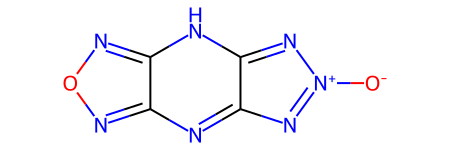

In [83]:
PandasTools.RenderImagesInAllDataFrames()
Chem.MolFromSmiles(df["SMILES"][150])